# South German Credit: exploratory data analysis

This notebook explores the South German Credit data after the checks in `datapreprocessing.ipynb`. It covers the class balance, numerical and categorical features, and how each feature relates to credit risk.

`credit_risk` is the target: **0 = bad**, **1 = good**. Only pandas and matplotlib are used.

## 1. Load and prepare the data
The preprocessing notebook found no nulls, no invalid category codes, and no duplicate rows, so no cleaning is repeated here. This notebook only repeats what it needs to run on its own: load the file, rename the columns, and build a readable copy (`eda_df`) where category codes are replaced by their meanings.

`df` keeps the numeric codes (used for correlations). `eda_df` holds the readable labels (used for charts and group summaries).

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

raw_folder = Path('Dataset/raw')
if not raw_folder.exists():
    raw_folder = Path('../Dataset/raw')

df = pd.read_csv(raw_folder / 'SouthGermanCredit.asc', sep=r'\s+')
print('Shape:', df.shape)
print('Total nulls:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

Shape: (1000, 21)
Total nulls: 0
Duplicate rows: 0


### Column names and category meanings
These are the same English names and code meanings used in the preprocessing notebook (from `codetable.txt`).

In [2]:
rename_map = {'laufkont': 'status',
 'laufzeit': 'duration',
 'moral': 'credit_history',
 'verw': 'purpose',
 'hoehe': 'amount',
 'sparkont': 'savings',
 'beszeit': 'employment_duration',
 'rate': 'installment_rate',
 'famges': 'personal_status_sex',
 'buerge': 'other_debtors',
 'wohnzeit': 'present_residence',
 'verm': 'property',
 'alter': 'age',
 'weitkred': 'other_installment_plans',
 'wohn': 'housing',
 'bishkred': 'number_credits',
 'beruf': 'job',
 'pers': 'people_liable',
 'telef': 'telephone',
 'gastarb': 'foreign_worker',
 'kredit': 'credit_risk'}

df = df.rename(columns=rename_map)

In [3]:
category_mappings = {'status': {1: 'no checking account',
            2: '... < 0 DM',
            3: '0<= ... < 200 DM',
            4: '... >= 200 DM / salary for at least 1 year'},
 'credit_history': {0: 'delay in paying off in the past',
                    1: 'critical account/other credits elsewhere',
                    2: 'no credits taken/all credits paid back duly',
                    3: 'existing credits paid back duly till now',
                    4: 'all credits at this bank paid back duly'},
 'purpose': {0: 'others',
             1: 'car (new)',
             2: 'car (used)',
             3: 'furniture/equipment',
             4: 'radio/television',
             5: 'domestic appliances',
             6: 'repairs',
             7: 'education',
             8: 'vacation',
             9: 'retraining',
             10: 'business'},
 'savings': {1: 'unknown/no savings account',
             2: '... <  100 DM',
             3: '100 <= ... <  500 DM',
             4: '500 <= ... < 1000 DM',
             5: '... >= 1000 DM'},
 'employment_duration': {1: 'unemployed',
                         2: '< 1 yr',
                         3: '1 <= ... < 4 yrs',
                         4: '4 <= ... < 7 yrs',
                         5: '>= 7 yrs'},
 'installment_rate': {1: '>= 35', 2: '25 <= ... < 35', 3: '20 <= ... < 25', 4: '< 20'},
 'personal_status_sex': {1: 'male : divorced/separated',
                         2: 'female : non-single or male : single',
                         3: 'male : married/widowed',
                         4: 'female : single'},
 'other_debtors': {1: 'none', 2: 'co-applicant', 3: 'guarantor'},
 'present_residence': {1: '< 1 yr', 2: '1 <= ... < 4 yrs', 3: '4 <= ... < 7 yrs', 4: '>= 7 yrs'},
 'property': {1: 'unknown / no property',
              2: 'car or other',
              3: 'building soc. savings agr./life insurance',
              4: 'real estate'},
 'other_installment_plans': {1: 'bank', 2: 'stores', 3: 'none'},
 'housing': {1: 'for free', 2: 'rent', 3: 'own'},
 'number_credits': {1: '1', 2: '2-3', 3: '4-5', 4: '>= 6'},
 'job': {1: 'unemployed/unskilled - non-resident',
         2: 'unskilled - resident',
         3: 'skilled employee/official',
         4: 'manager/self-empl./highly qualif. employee'},
 'people_liable': {1: '3 or more', 2: '0 to 2'},
 'telephone': {1: 'no', 2: 'yes (under customer name)'},
 'foreign_worker': {1: 'yes', 2: 'no'},
 'credit_risk': {0: 'bad', 1: 'good'}}

In [4]:
numerical_features = ['duration', 'amount', 'age']

nominal_features = [
    'status', 'credit_history', 'purpose', 'savings', 'personal_status_sex',
    'other_debtors', 'other_installment_plans', 'housing', 'people_liable',
    'telephone', 'foreign_worker'
]

ordinal_features = [
    'employment_duration', 'installment_rate', 'present_residence',
    'property', 'number_credits', 'job'
]

# Readable copy: replace each category code with its meaning.
eda_df = df.copy()
for column, mapping in category_mappings.items():
    eda_df[column] = pd.Categorical(df[column].map(mapping),
                                    categories=list(mapping.values()))

# 1 if the applicant is a bad credit risk, 0 otherwise (the mean of this is the bad rate).
eda_df['is_bad'] = (df['credit_risk'] == 0).astype(int)

bad_color = 'tab:red'
good_color = 'tab:blue'

display(eda_df.head())

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk,is_bad
0,no checking account,18,all credits at this bank paid back duly,car (used),1049,unknown/no savings account,< 1 yr,< 20,female : non-single or male : single,none,...,21,none,for free,1,skilled employee/official,0 to 2,no,no,good,0
1,no checking account,9,all credits at this bank paid back duly,others,2799,unknown/no savings account,1 <= ... < 4 yrs,25 <= ... < 35,male : married/widowed,none,...,36,none,for free,2-3,skilled employee/official,3 or more,no,no,good,0
2,... < 0 DM,12,no credits taken/all credits paid back duly,retraining,841,... < 100 DM,4 <= ... < 7 yrs,25 <= ... < 35,female : non-single or male : single,none,...,23,none,for free,1,unskilled - resident,0 to 2,no,no,good,0
3,no checking account,12,all credits at this bank paid back duly,others,2122,unknown/no savings account,1 <= ... < 4 yrs,20 <= ... < 25,male : married/widowed,none,...,39,none,for free,2-3,unskilled - resident,3 or more,no,yes,good,0
4,no checking account,12,all credits at this bank paid back duly,others,2171,unknown/no savings account,1 <= ... < 4 yrs,< 20,male : married/widowed,none,...,38,bank,rent,2-3,unskilled - resident,0 to 2,no,yes,good,0


## 2. Dataset overview
Check the size, data types, and basic summaries before plotting. Numerical features are summarised with `describe()`. Categorical features show how many categories they have, the most common category (`top`), and how many applicants fall in it (`freq`).

In [5]:
eda_df.info()

print('Numerical features:')
display(df[numerical_features].describe().round(1))

print('Categorical features:')
display(eda_df[nominal_features + ordinal_features].describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   status                   1000 non-null   category
 1   duration                 1000 non-null   int64   
 2   credit_history           1000 non-null   category
 3   purpose                  1000 non-null   category
 4   amount                   1000 non-null   int64   
 5   savings                  1000 non-null   category
 6   employment_duration      1000 non-null   category
 7   installment_rate         1000 non-null   category
 8   personal_status_sex      1000 non-null   category
 9   other_debtors            1000 non-null   category
 10  present_residence        1000 non-null   category
 11  property                 1000 non-null   category
 12  age                      1000 non-null   int64   
 13  other_installment_plans  1000 non-null   category
 14  housing             

,duration,amount,age
count,1000.0,1000.0,1000.0
mean,20.9,3271.2,35.5
std,12.1,2822.8,11.4
min,4.0,250.0,19.0
25%,12.0,1365.5,27.0
50%,18.0,2319.5,33.0
75%,24.0,3972.2,42.0
max,72.0,18424.0,75.0


Categorical features:


,count,unique,top,freq
status,1000,4,... >= 200 DM / salary for at least 1 year,394
credit_history,1000,5,no credits taken/all credits paid back duly,530
purpose,1000,10,furniture/equipment,280
savings,1000,5,unknown/no savings account,603
personal_status_sex,1000,4,male : married/widowed,548
other_debtors,1000,3,none,907
other_installment_plans,1000,3,none,814
housing,1000,3,rent,714
people_liable,1000,2,0 to 2,845
telephone,1000,2,no,596


## 3. Target distribution
Check how many applicants are good and bad credit risks. If one class is much larger, accuracy alone is a misleading metric, so models need to be judged with measures such as recall, precision, or F1 for the bad class.

,count,percent
credit_risk,,
good,700,70.0
bad,300,30.0


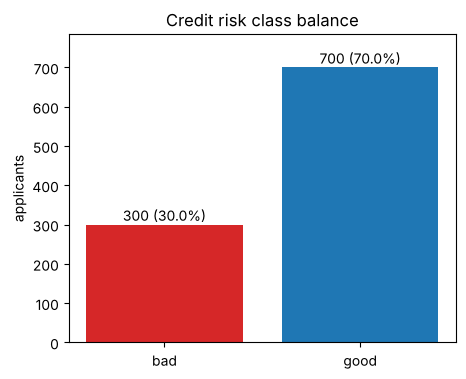

In [6]:
target_counts = eda_df['credit_risk'].value_counts()
target_percent = (target_counts / len(eda_df) * 100).round(1)
display(pd.DataFrame({'count': target_counts, 'percent': target_percent}))

plt.figure(figsize=(5, 4))
plt.bar(['bad', 'good'], [target_counts['bad'], target_counts['good']],
        color=[bad_color, good_color])
for i, label in enumerate(['bad', 'good']):
    plt.text(i, target_counts[label] + 10,
             f'{target_counts[label]} ({target_percent[label]}%)', ha='center')
plt.ylim(0, target_counts.max() * 1.12)
plt.title('Credit risk class balance')
plt.ylabel('applicants')
plt.show()

## 4. Numerical feature distributions
Look at the shape of `duration`, `amount`, and `age`. The dashed line is the mean and the dotted line is the median; a large gap between them signals skew. Outliers are counted with the 1.5 x IQR rule but **not removed**, because the preprocessing notebook decided not to drop large values solely for being large.

Duration is in months and age is in years. `amount` is on the supplied transformed scale, so it is not exact currency.

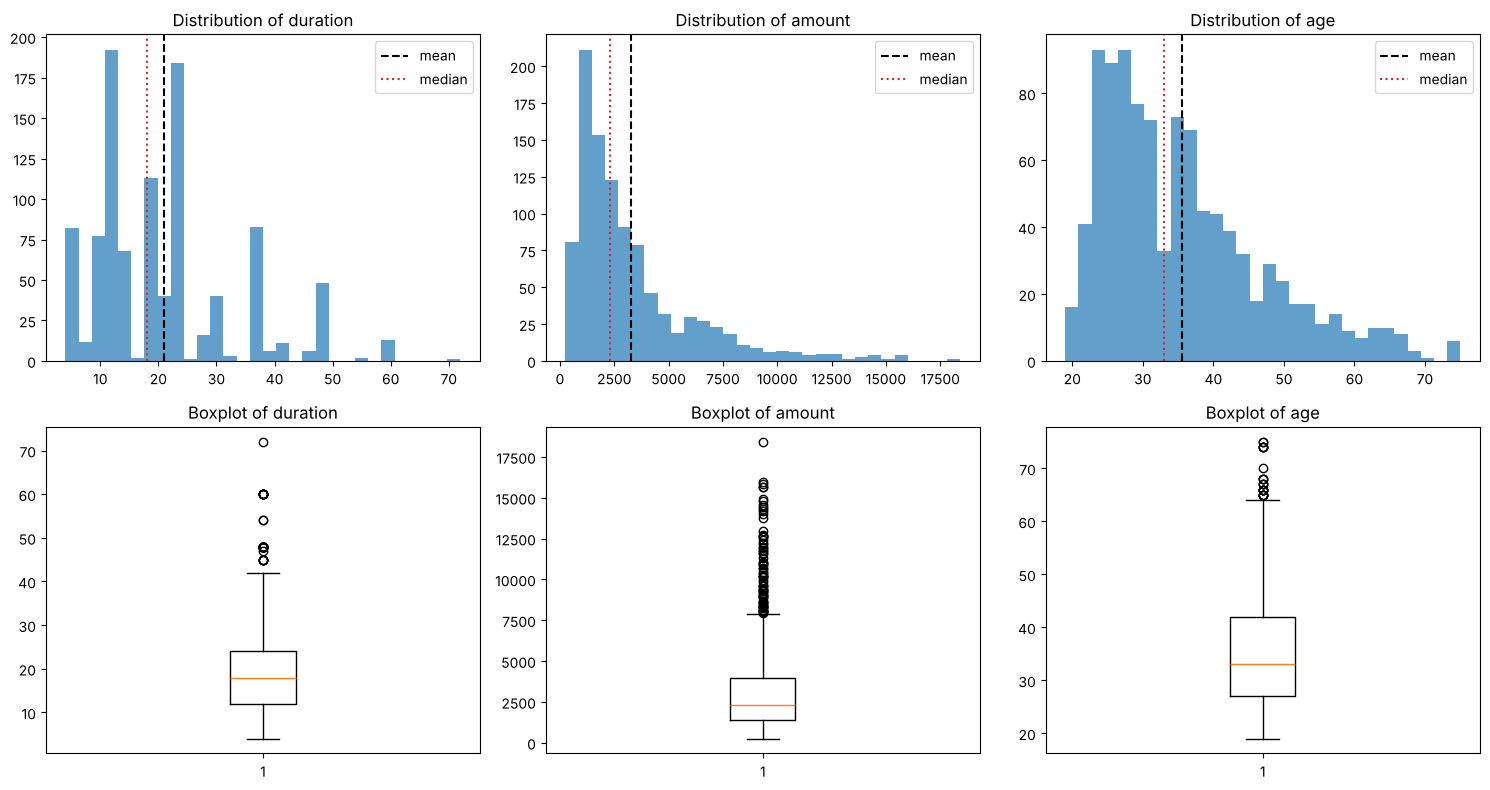

,skewness,iqr_outliers
duration,1.09,70
amount,1.95,72
age,1.02,23


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, column in enumerate(numerical_features):
    axes[0, i].hist(df[column], bins=30, color='tab:blue', alpha=0.7)
    axes[0, i].axvline(df[column].mean(), color='black', linestyle='--', label='mean')
    axes[0, i].axvline(df[column].median(), color='tab:red', linestyle=':', label='median')
    axes[0, i].set_title(f'Distribution of {column}')
    axes[0, i].legend()

    axes[1, i].boxplot(df[column])
    axes[1, i].set_title(f'Boxplot of {column}')

plt.tight_layout()
plt.show()

def count_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum())

numeric_shape = pd.DataFrame({
    'skewness': df[numerical_features].skew().round(2),
    'iqr_outliers': [count_outliers(df[column]) for column in numerical_features]
})
display(numeric_shape)

## 5. Numerical features vs credit risk
Compare the numerical features between good and bad applicants. If the boxes for the two classes barely overlap, the feature separates them well. If they sit on top of each other, the feature adds little on its own.

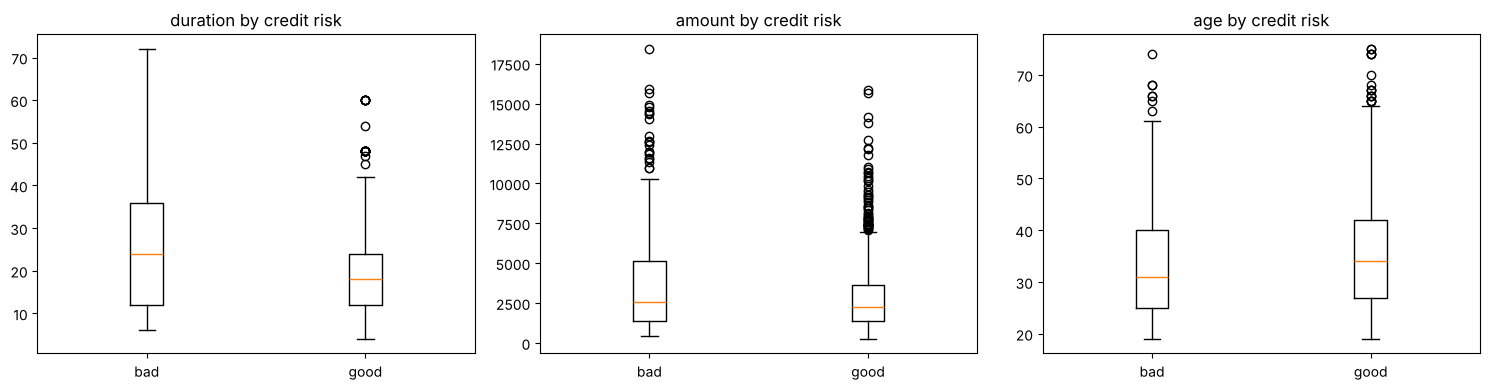

duration         amount           age       
                mean median    mean  median  mean median
credit_risk                                             
bad             24.9   24.0  3938.1  2574.5  34.0   31.0
good            19.2   18.0  2985.4  2244.0  36.2   34.0

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, numerical_features):
    bad_values = df[df['credit_risk'] == 0][column]
    good_values = df[df['credit_risk'] == 1][column]
    ax.boxplot([bad_values, good_values])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['bad', 'good'])
    ax.set_title(f'{column} by credit risk')

plt.tight_layout()
plt.show()

display(eda_df.groupby('credit_risk', observed=True)[numerical_features].agg(['mean', 'median']).round(1))

## 6. Correlations
Correlations use the numeric codes in `df`. The target is coded 0 = bad and 1 = good, so a **negative** correlation with `credit_risk` means larger values go with bad credit. Correlations between the numerical features show whether any of them carry overlapping information.

,duration,amount,age,credit_risk
duration,1.00,0.62,-0.04,-0.21
amount,0.62,1.00,0.03,-0.15
age,-0.04,0.03,1.00,0.09
credit_risk,-0.21,-0.15,0.09,1.00


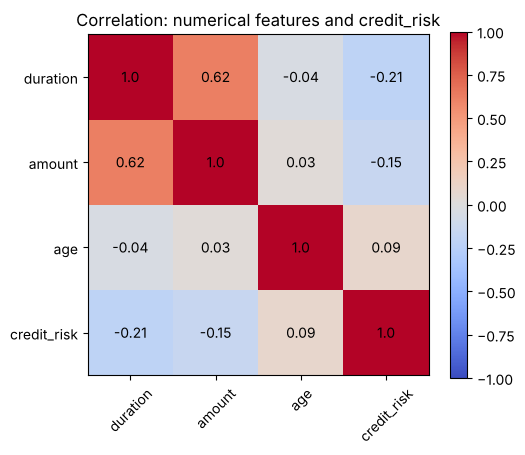

In [9]:
correlation = df[numerical_features + ['credit_risk']].corr().round(2)
display(correlation)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation.columns)))
ax.set_xticklabels(correlation.columns, rotation=45)
ax.set_yticks(range(len(correlation.columns)))
ax.set_yticklabels(correlation.columns)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        ax.text(j, i, correlation.iloc[i, j], ha='center', va='center')
fig.colorbar(image)
ax.set_title('Correlation: numerical features and credit_risk')
plt.show()

## 7. Nominal features vs credit risk
For each nominal feature, the chart shows the **bad credit rate** (percentage of applicants with `credit_risk` = bad) for every category. The dashed line is the overall bad rate. Bars above it are red, bars at or below it are grey, and `n` is the number of applicants in the category.

Categories are sorted from highest to lowest bad rate. Treat small categories (roughly `n` below 30) with caution, because their rates move a lot with just a few applicants.

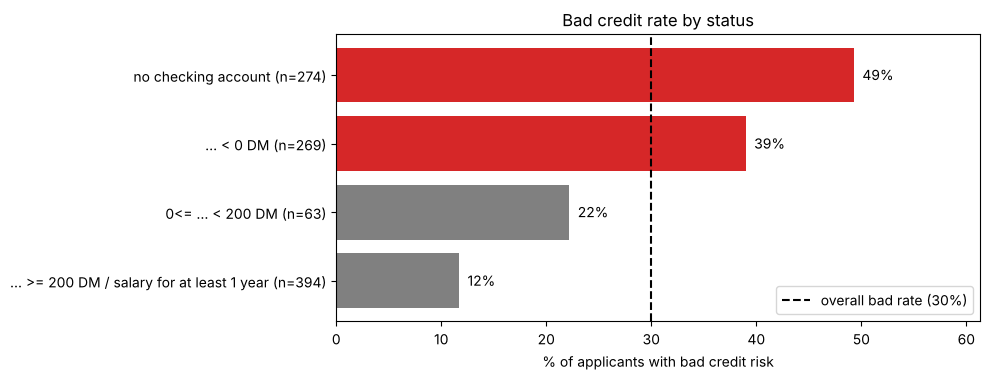

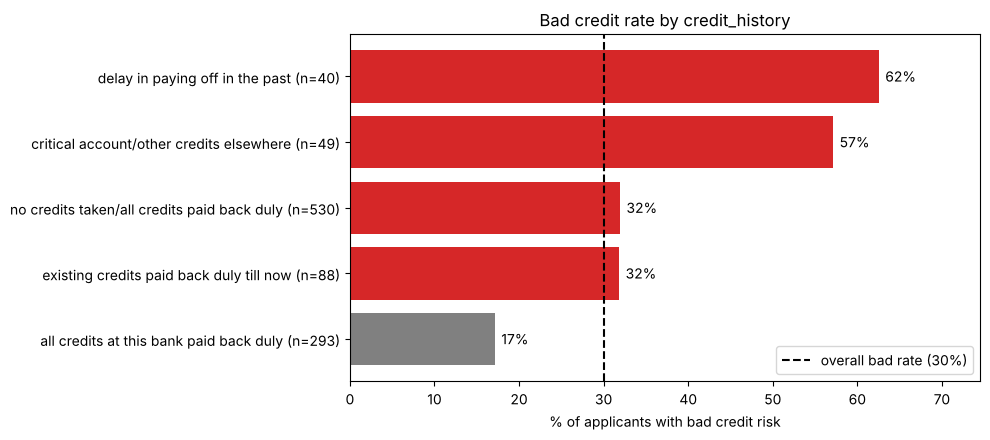

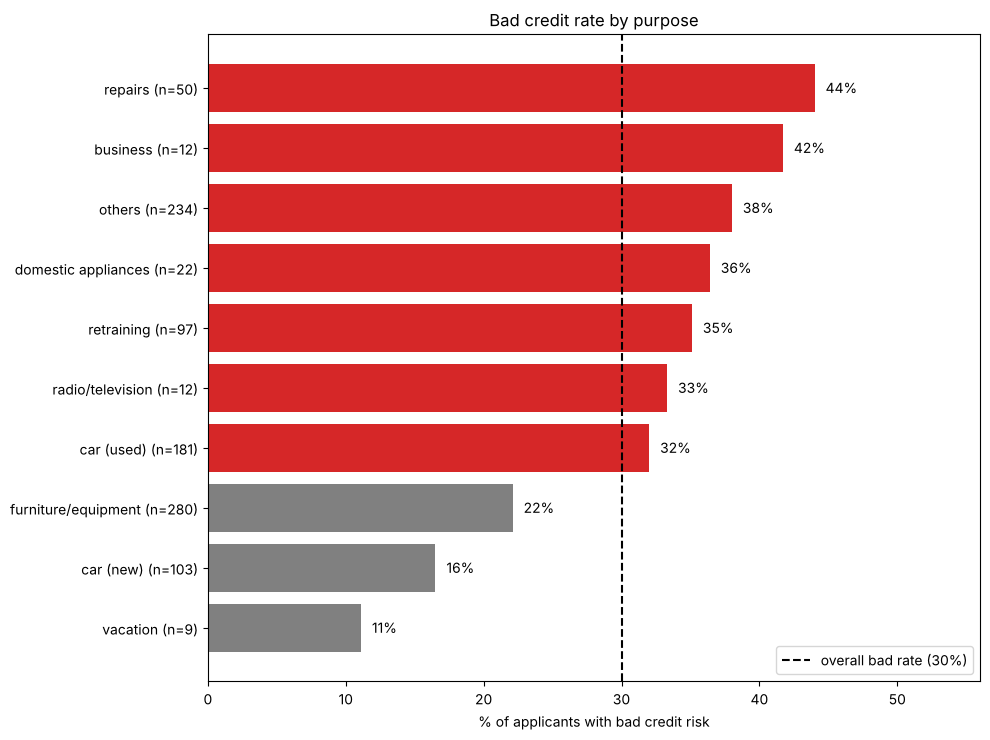

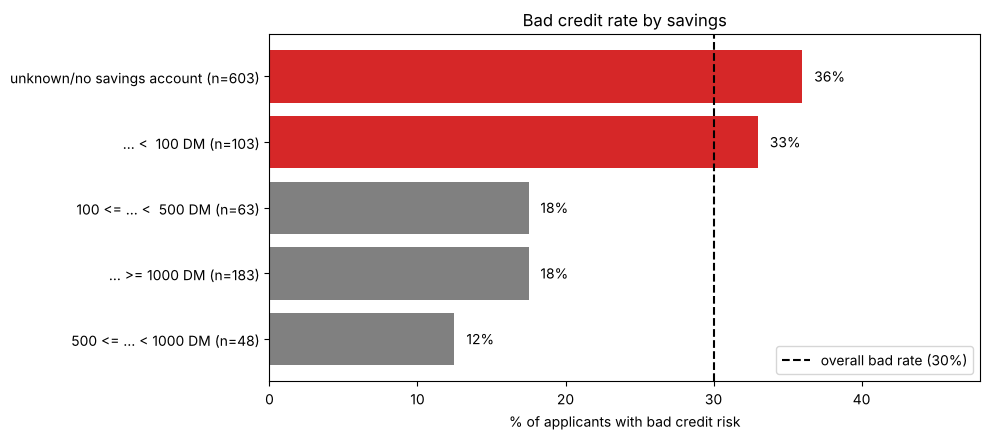

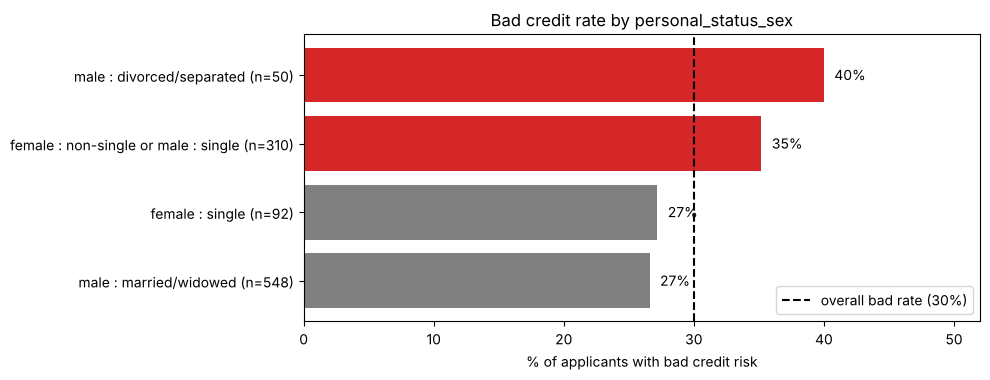

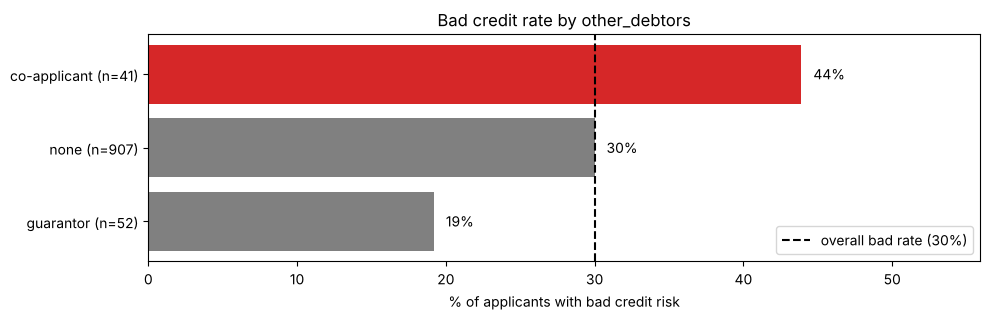

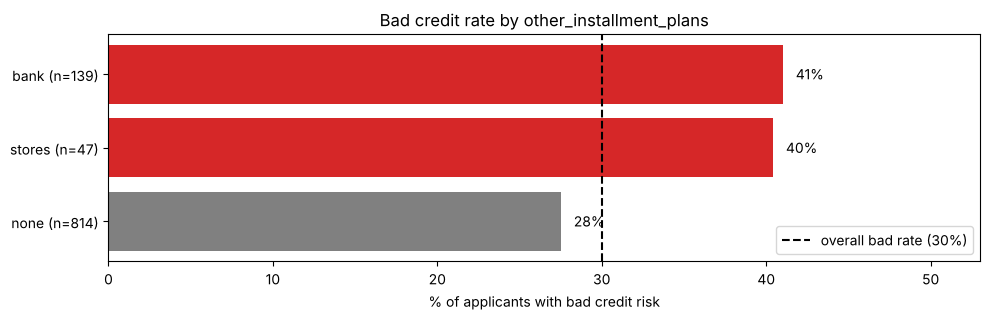

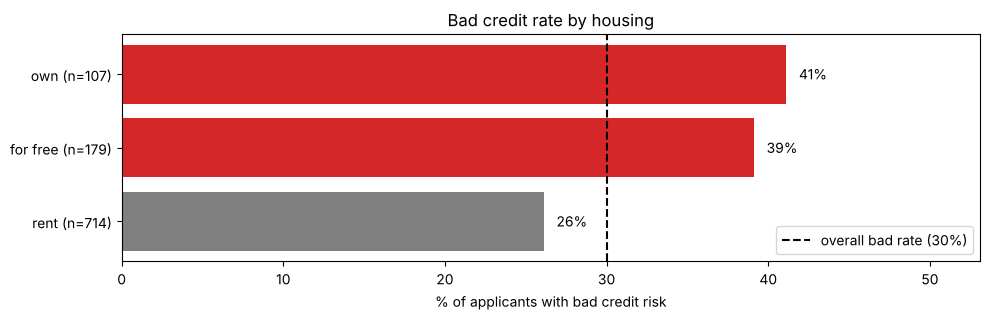

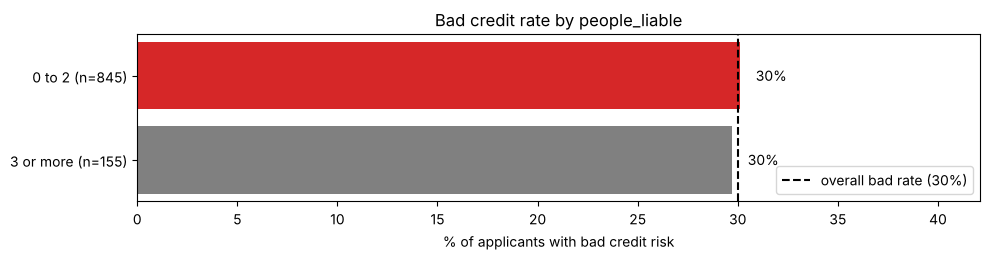

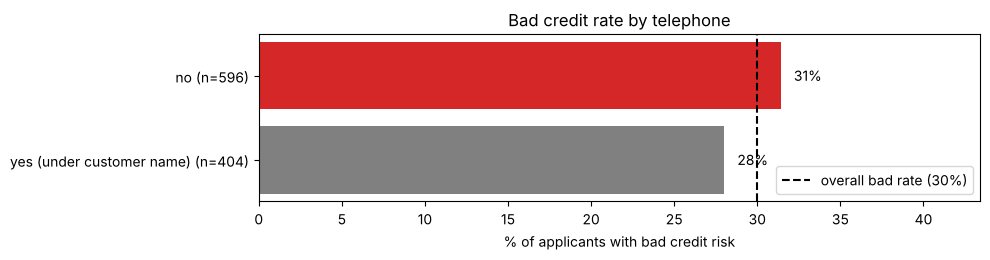

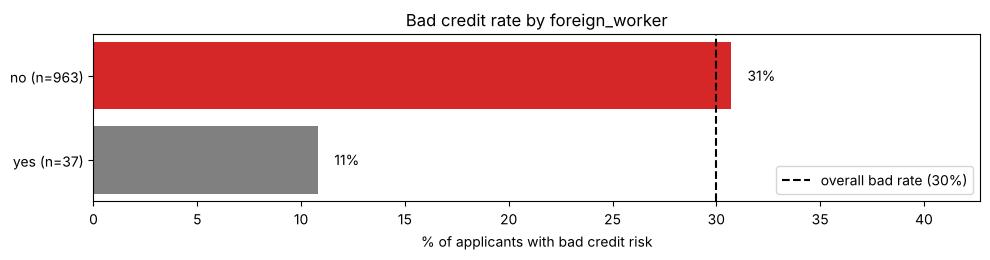

In [10]:
overall_bad_rate = eda_df['is_bad'].mean() * 100

def bad_rate_table(feature):
    group = eda_df.groupby(feature, observed=True)
    table = pd.DataFrame()
    table['applicants'] = group.size()
    table['bad_rate_pct'] = (group['is_bad'].mean() * 100).round(1)
    return table

def plot_bad_rate(feature, sort_by_rate=True):
    table = bad_rate_table(feature)
    if sort_by_rate:
        table = table.sort_values('bad_rate_pct', ascending=False)

    labels = []
    colors = []
    for category, row in table.iterrows():
        labels.append(f'{category} (n={int(row["applicants"])})')
        if row['bad_rate_pct'] > overall_bad_rate:
            colors.append(bad_color)
        else:
            colors.append('gray')

    plt.figure(figsize=(10, 0.6 * len(table) + 1.5))
    plt.barh(labels, table['bad_rate_pct'], color=colors)
    plt.axvline(overall_bad_rate, color='black', linestyle='--',
                label=f'overall bad rate ({overall_bad_rate:.0f}%)')
    for i, rate in enumerate(table['bad_rate_pct']):
        plt.text(rate + 0.8, i, f'{rate:.0f}%', va='center')
    plt.gca().invert_yaxis()
    plt.xlim(0, table['bad_rate_pct'].max() + 12)
    plt.title(f'Bad credit rate by {feature}')
    plt.xlabel('% of applicants with bad credit risk')
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

for feature in nominal_features:
    plot_bad_rate(feature, sort_by_rate=True)

## 8. Ordinal features vs credit risk
Ordinal features keep their natural order instead of being sorted by bad rate, so a trend (for example, risk falling as employment duration rises) is easy to see. A Spearman correlation with the target summarises each trend in one number. Negative means higher codes go with more bad credit, and values near 0 mean no clear trend. This is only meaningful when the codes are ordered the way the feature is, so read it together with the charts.

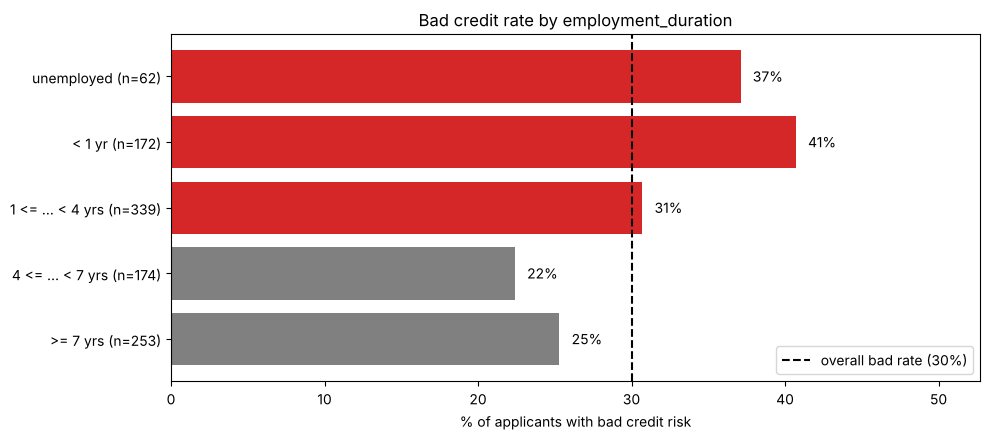

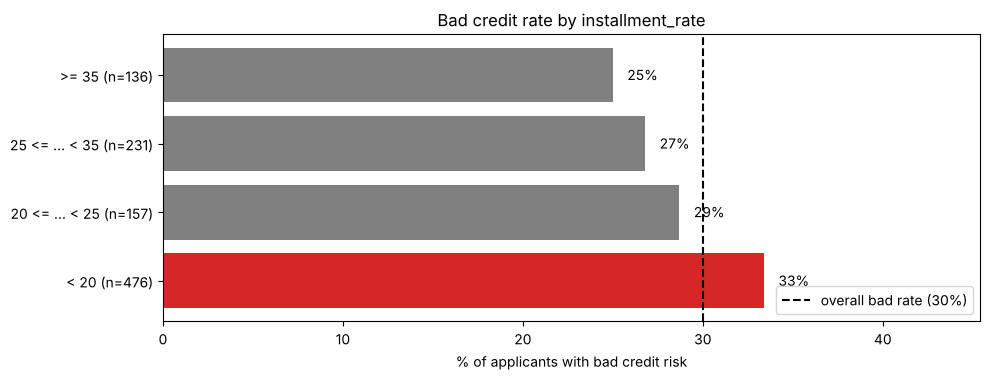

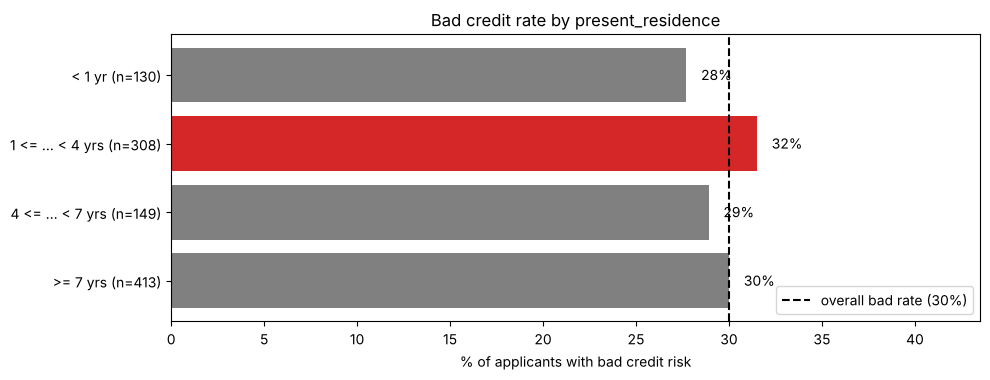

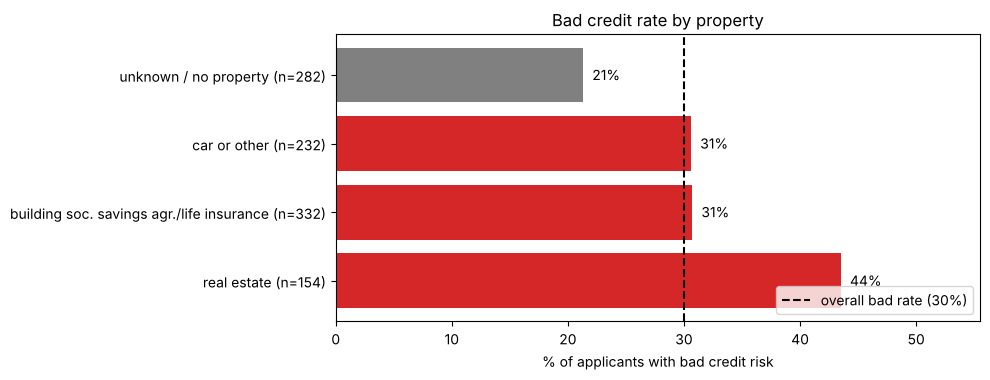

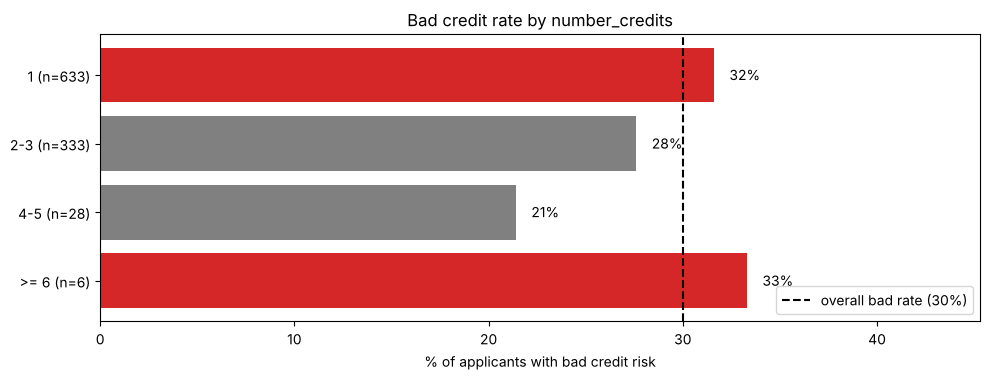

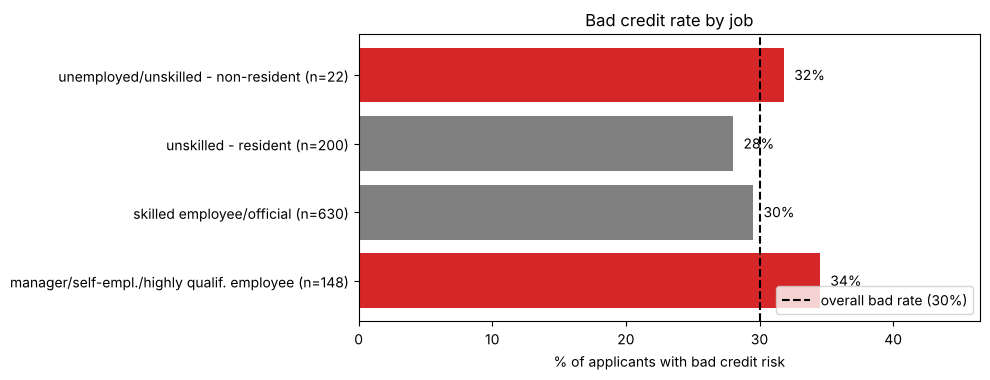

,spearman_with_credit_risk
property,-0.14
installment_rate,-0.07
job,-0.04
present_residence,-0.00
number_credits,0.05
employment_duration,0.12


In [11]:
for feature in ordinal_features:
    plot_bad_rate(feature, sort_by_rate=False)

ordinal_trend = df[ordinal_features + ['credit_risk']].corr(method='spearman')['credit_risk']
ordinal_trend = ordinal_trend.drop('credit_risk').round(2).sort_values()
display(ordinal_trend.to_frame('spearman_with_credit_risk'))

## 9. Grouped numerical features
Numerical features can hide non-linear patterns, so group them into bands and compare the bad rate across bands. Amount is split into quartiles because its scale is not real currency. The scatter plot checks whether large, long loans are riskier.

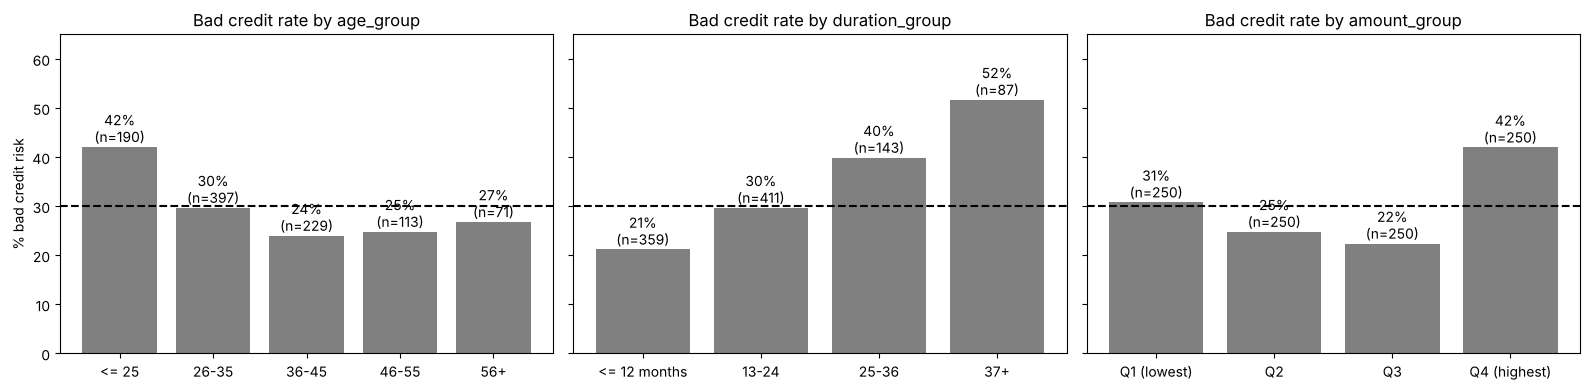

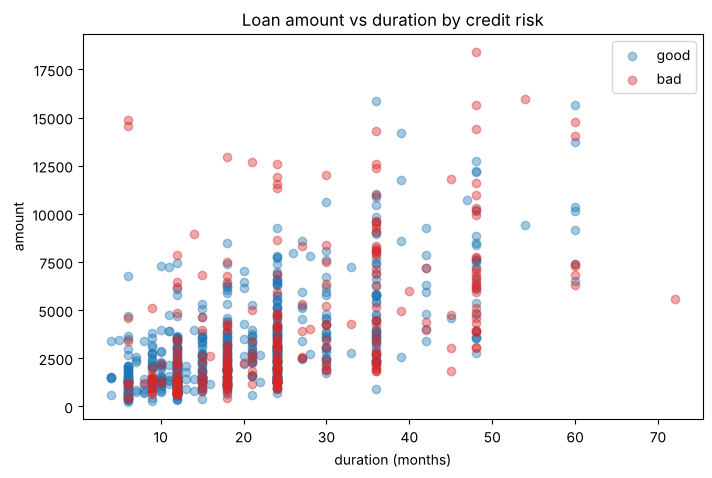

In [12]:
eda_df['age_group'] = pd.cut(df['age'], bins=[0, 25, 35, 45, 55, 100],
                             labels=['<= 25', '26-35', '36-45', '46-55', '56+'])
eda_df['duration_group'] = pd.cut(df['duration'], bins=[0, 12, 24, 36, 100],
                                  labels=['<= 12 months', '13-24', '25-36', '37+'])
eda_df['amount_group'] = pd.qcut(df['amount'], q=4,
                                 labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for ax, feature in zip(axes, ['age_group', 'duration_group', 'amount_group']):
    table = bad_rate_table(feature)
    ax.bar(table.index.astype(str), table['bad_rate_pct'], color='gray')
    ax.axhline(overall_bad_rate, color='black', linestyle='--')
    for i in range(len(table)):
        rate = table['bad_rate_pct'].iloc[i]
        n = int(table['applicants'].iloc[i])
        ax.text(i, rate + 1, f'{rate:.0f}%\n(n={n})', ha='center')
    ax.set_title(f'Bad credit rate by {feature}')
    ax.set_ylim(0, 65)

axes[0].set_ylabel('% bad credit risk')
plt.tight_layout()
plt.show()

bad_rows = df[df['credit_risk'] == 0]
good_rows = df[df['credit_risk'] == 1]

plt.figure(figsize=(8, 5))
plt.scatter(good_rows['duration'], good_rows['amount'], color=good_color, alpha=0.4, label='good')
plt.scatter(bad_rows['duration'], bad_rows['amount'], color=bad_color, alpha=0.4, label='bad')
plt.title('Loan amount vs duration by credit risk')
plt.xlabel('duration (months)')
plt.ylabel('amount')
plt.legend()
plt.show()

## 10. Feature overview
Rank the categorical features by how much the bad rate changes across their categories (highest bad rate minus lowest). Only categories with at least 30 applicants are used so tiny groups do not dominate. This is a quick screening measure, not a statistical test, and it cannot show whether a feature is useful once combined with the others.

In [13]:
min_group_size = 30
rows = []

for feature in nominal_features + ordinal_features:
    table = bad_rate_table(feature)
    table = table[table['applicants'] >= min_group_size]
    lowest = table['bad_rate_pct'].min()
    highest = table['bad_rate_pct'].max()
    rows.append({
        'feature': feature,
        'type': 'nominal' if feature in nominal_features else 'ordinal',
        'lowest_bad_rate_pct': lowest,
        'highest_bad_rate_pct': highest,
        'spread_pct_points': round(highest - lowest, 1)
    })

feature_spread = pd.DataFrame(rows).sort_values('spread_pct_points', ascending=False)
display(feature_spread.reset_index(drop=True))

,feature,type,lowest_bad_rate_pct,highest_bad_rate_pct,spread_pct_points
0,credit_history,nominal,17.1,62.5,45.4
1,status,nominal,11.7,49.3,37.6
2,purpose,nominal,16.5,44.0,27.5
3,other_debtors,nominal,19.2,43.9,24.7
4,savings,nominal,12.5,36.0,23.5
5,property,ordinal,21.3,43.5,22.2
6,foreign_worker,nominal,10.8,30.7,19.9
7,employment_duration,ordinal,22.4,40.7,18.3
8,housing,nominal,26.1,41.1,15.0
9,other_installment_plans,nominal,27.5,41.0,13.5


## 11. EDA findings

**Target**
- There are 1,000 applicants: 700 good (70%) and 300 bad (30%).
- The classes are imbalanced, so use stratified splits and judge models with recall, precision, or F1 for the bad class, not just accuracy.

**Numerical features**
- `duration`, `amount`, and `age` are all right-skewed. Outliers were found but not removed.
- `duration` and `amount` are moderately correlated (0.62). `age` is almost unrelated to both.
- Each feature has only a weak correlation with credit risk (duration -0.21, amount -0.15, age 0.09).
- Longer loans are riskier. The bad rate is 21% for loans of 12 months or less and 52% for loans of 37 months or more.
- Amount is only riskier in the highest quartile (42% bad, against 22% to 31% in the other three).
- Applicants aged 25 or under have a 42% bad rate, against 24% to 30% for older groups.

**Categorical features**
- The features with the clearest link to credit risk are:
  - `credit_history`: 62.5% bad for past payment delays, against 17% when all credits at this bank were paid back duly.
  - `status`: 49% bad with no checking account, against 12% for 200 DM or more.
  - `savings`: 36% bad for unknown/no savings, against 12.5% for 500-1000 DM.
  - `other_debtors`: 44% bad with a co-applicant, against 19% with a guarantor.
- The ordinal features show only weak trends. The clearest is `employment_duration`: longer employment goes with lower risk.
- `installment_rate`, `job`, `number_credits`, `present_residence`, `telephone`, and `people_liable` barely change the bad rate.

**Points to double-check**
- Some categories are small (for example `foreign_worker` = yes has only 37 applicants), so their bad rates are unstable.
- Some results look odd under the codetable labels. `property` = "real estate" has the highest bad rate (44%) and "unknown / no property" the lowest (21%), and `purpose` = "others" holds 234 applicants. Check these labels against the dataset documentation before drawing conclusions.

**For modelling**
- One-hot encode the nominal features and consider a log transform for `amount`.
- Watch the `duration`/`amount` correlation in linear models.
- Merge or regularise very small categories.